# Group 4 wine subset

This notebook selects every review whose `variety` belongs to batch/group 4 in `wine_style_groups_final.csv`.

In [23]:
import pandas as pd

wine_reviews = pd.read_csv('winemag-data-130k-v2.csv')
style_groups = pd.read_csv('wine_style_groups_final.csv')

# Collect the exact variety names assigned to group 4.
group_4_varieties = (
    style_groups.loc[style_groups['batch'].eq(4), 'varieties']
    .str.split(';')
    .explode()
    .str.strip()
    .dropna()
    .unique()
)

# `variety` is the matching column in the Wine Enthusiast data.
group_4_wines = wine_reviews.loc[
    wine_reviews['variety'].isin(group_4_varieties)
].copy()

# Remove the original CSV index column, if present.
group_4_wines = group_4_wines.drop(columns=['Unnamed: 0'], errors='ignore')

group_4_wines.to_csv('winemag_group_4_wines.csv', index=False)

print(f'Group 4 varieties: {len(group_4_varieties):,}')
print(f'Group 4 wine reviews: {len(group_4_wines):,}')
group_4_wines.head()

Group 4 varieties: 113
Group 4 wine reviews: 26,249


,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery
1,Portugal,"This is ripe and fruity, a wine that is smooth...",Avidagos,87,15.0,Douro,NaN,NaN,Roger Voss,@vossroger,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red,Quinta dos Avidagos
2,US,"Tart and snappy, the flavors of lime flesh and...",NaN,87,14.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris,Rainstorm
3,US,"Pineapple rind, lemon pith and orange blossom ...",Reserve Late Harvest,87,13.0,Michigan,Lake Michigan Shore,NaN,Alexander Peartree,NaN,St. Julian 2013 Reserve Late Harvest Riesling ...,Riesling,St. Julian
9,France,This has great depth of flavor with its fresh ...,Les Natures,87,27.0,Alsace,Alsace,NaN,Roger Voss,@vossroger,Jean-Baptiste Adam 2012 Les Natures Pinot Gris...,Pinot Gris,Jean-Baptiste Adam
15,Germany,Zesty orange peels and apple notes abound in t...,Devon,87,24.0,Mosel,NaN,NaN,Anna Lee C. Iijima,NaN,Richard Böcking 2013 Devon Riesling (Mosel),Riesling,Richard Böcking


In [24]:
# Optional check: review counts by Group 4 style.
group_4_style_counts = (
    style_groups.loc[style_groups['batch'].eq(4), ['style_group', 'num_reviews']]
    .sort_values('num_reviews', ascending=False)
)
group_4_style_counts

,style_group,num_reviews
19,Bordeaux-style Red Blend,13243
20,Riesling,6663
21,Iberian Reds,4506
22,Pinot Gris & Pinot Blanc,4028
23,Tempranillo,2960
24,Rhône Whites,2584


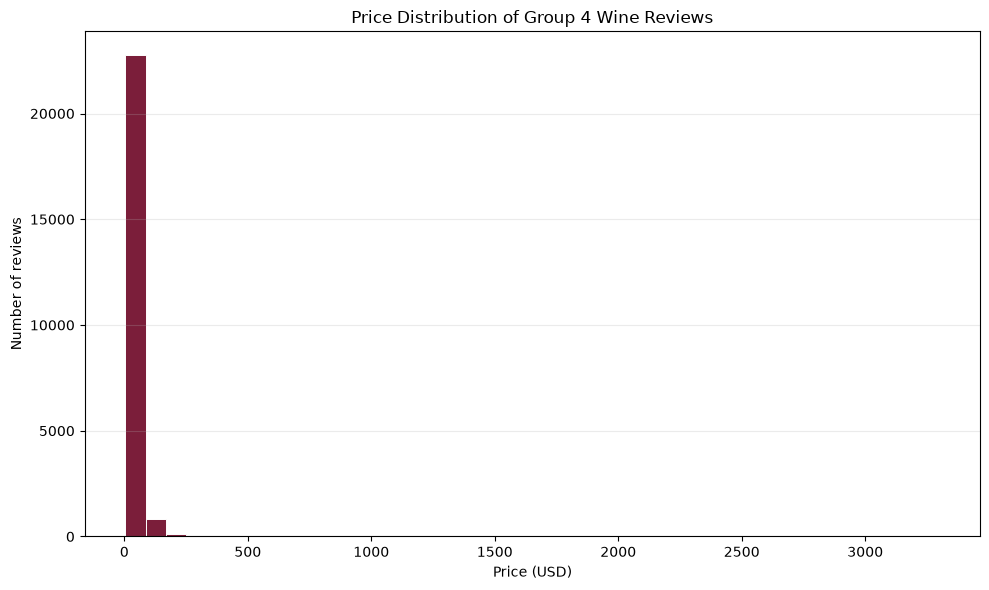

Included 23,796 reviews with a positive recorded price.


In [25]:
import matplotlib.pyplot as plt

# Plot the original dollar values on a linear x-axis.
prices = group_4_wines.loc[group_4_wines['price'].gt(0), 'price'].dropna()

fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(prices, bins=40, color='#7B1E3A', edgecolor='white', linewidth=0.7)
ax.set_title('Price Distribution of Group 4 Wine Reviews')
ax.set_xlabel('Price (USD)')
ax.set_ylabel('Number of reviews')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

print(f'Included {len(prices):,} reviews with a positive recorded price.')

In [26]:
print(max(group_4_wines.price))
print(min(group_4_wines.price))
print(group_4_wines.price.mean())
print(group_4_wines.price.median())

3300.0
4.0
33.2922339889057
23.0


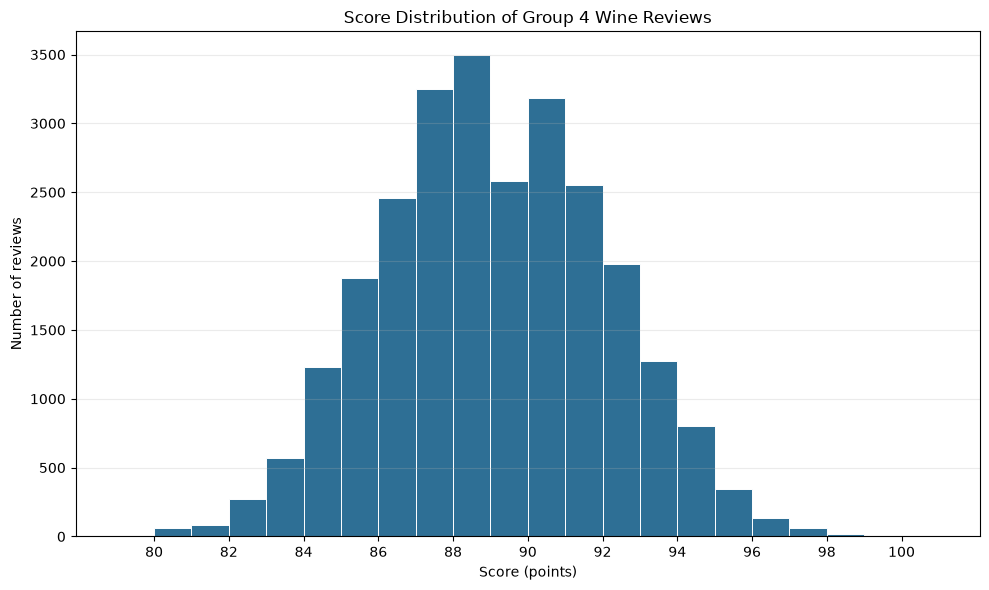

Average score: 88.6
Median score: 88


In [27]:
# Score distribution: one bin per whole-number Wine Enthusiast rating.
scores = group_4_wines['points'].dropna()
bins = range(int(scores.min()) - 1, int(scores.max()) + 2)

fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(scores, bins=bins, align='mid', color='#2E6F95', edgecolor='white', linewidth=0.7)
ax.set_title('Score Distribution of Group 4 Wine Reviews')
ax.set_xlabel('Score (points)')
ax.set_ylabel('Number of reviews')
ax.set_xticks(range(int(scores.min()), int(scores.max()) + 1, 2))
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

print(f'Average score: {scores.mean():.1f}')
print(f'Median score: {scores.median():.0f}')

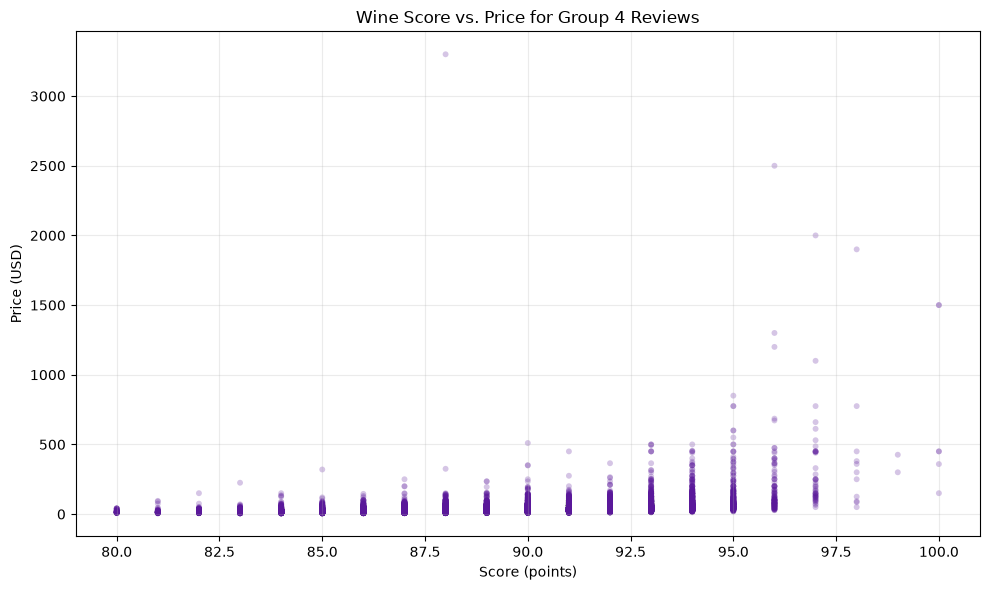

Pearson correlation: 0.345


In [28]:
# Compare each wine's review score with its listed price.
points_price = group_4_wines.loc[
    group_4_wines['points'].notna() & group_4_wines['price'].gt(0),
    ['points', 'price']
].dropna()

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(
    points_price['points'], points_price['price'],
    alpha=0.25, s=18, color='#5A189A', edgecolors='none'
)
ax.set_title('Wine Score vs. Price for Group 4 Reviews')
ax.set_xlabel('Score (points)')
ax.set_ylabel('Price (USD)')
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(f'Pearson correlation: {points_price["points"].corr(points_price["price"]):.3f}')

## Regional distribution

These summaries show where Group 4 wines in the review data are produced and the most frequently reviewed province in each country.

,country,review_count,percent_of_reviews
0,US,8537,32.5
1,France,6754,25.7
2,Portugal,2877,11.0
3,Spain,2669,10.2
4,Germany,1848,7.0
5,Italy,848,3.2
6,Chile,772,2.9
7,Austria,673,2.6
8,Argentina,357,1.4
9,Australia,297,1.1


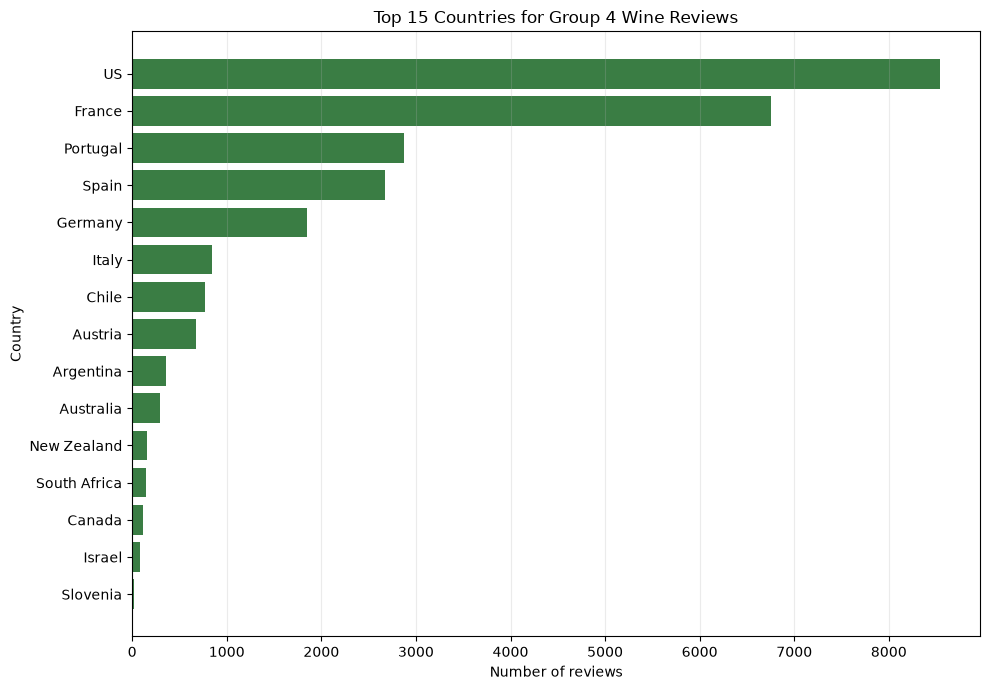

In [29]:
# Country distribution for Group 4 wine reviews.
country_counts = (
    group_4_wines['country']
    .dropna()
    .value_counts()
    .rename_axis('country')
    .reset_index(name='review_count')
)
country_counts['percent_of_reviews'] = (
    country_counts['review_count'] / country_counts['review_count'].sum() * 100
).round(1)

display(country_counts)

fig, ax = plt.subplots(figsize=(10, 7))
top_countries = country_counts.head(15).sort_values('review_count')
ax.barh(top_countries['country'], top_countries['review_count'], color='#3A7D44')
ax.set_title('Top 15 Countries for Group 4 Wine Reviews')
ax.set_xlabel('Number of reviews')
ax.set_ylabel('Country')
ax.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()

In [30]:
# Most frequently reviewed province within each country.
province_counts = (
    group_4_wines.dropna(subset=['country', 'province'])
    .groupby(['country', 'province'])
    .size()
    .reset_index(name='review_count')
)
top_province_by_country = (
    province_counts.sort_values(
        ['country', 'review_count', 'province'],
        ascending=[True, False, True]
    )
    .groupby('country', as_index=False)
    .first()
    .sort_values('review_count', ascending=False)
    .rename(columns={'province': 'most_reviewed_province'})
)

top_province_by_country

,country,most_reviewed_province,review_count
10,France,Bordeaux,4629
30,US,California,3479
28,Spain,Northern Spain,2302
11,Germany,Mosel,1020
22,Portugal,Douro,947
15,Italy,Northeastern Italy,688
0,Argentina,Mendoza Province,323
6,Chile,Colchagua Valley,222
1,Australia,South Australia,176
2,Austria,Wachau,158


In [31]:
# Number of Group 4 reviews written by each reviewer with a Twitter handle.
reviewer_handle_counts = (
    group_4_wines['taster_twitter_handle']
    .dropna()
    .astype(str)
    .str.strip()
    .loc[lambda handles: handles.ne('')]
    .value_counts()
    .rename_axis('taster_twitter_handle')
    .reset_index(name='review_count')
)
reviewer_handle_counts

,taster_twitter_handle,review_count
0,@vossroger,8715
1,@wineschach,3789
2,@paulgwine,2131
3,@wawinereport,1278
4,@AnneInVino,1234
5,@JoeCz,1075
6,@vboone,788
7,@mattkettmann,750
8,@gordone_cellars,401
9,@kerinokeefe,364


## Target class balance

The prediction target is `variety`. Class counts show whether a model will have enough examples to learn each variety and whether rare classes need to be combined or excluded.

,variety,review_count,percent_of_reviews
0,Bordeaux-style Red Blend,6915,26.34
1,Riesling,5189,19.77
2,Portuguese Red,2466,9.39
3,Tempranillo,1810,6.90
4,Pinot Gris,1455,5.54
...,...,...,...
105,Merlot-Petite Verdot,1,0.00
106,Ramisco,1,0.00
107,Babosa Negro,1,0.00
108,Parraleta,1,0.00


Varieties with at least  10 reviews: 62
Varieties with at least  25 reviews: 38
Varieties with at least  50 reviews: 26
Varieties with at least 100 reviews: 22


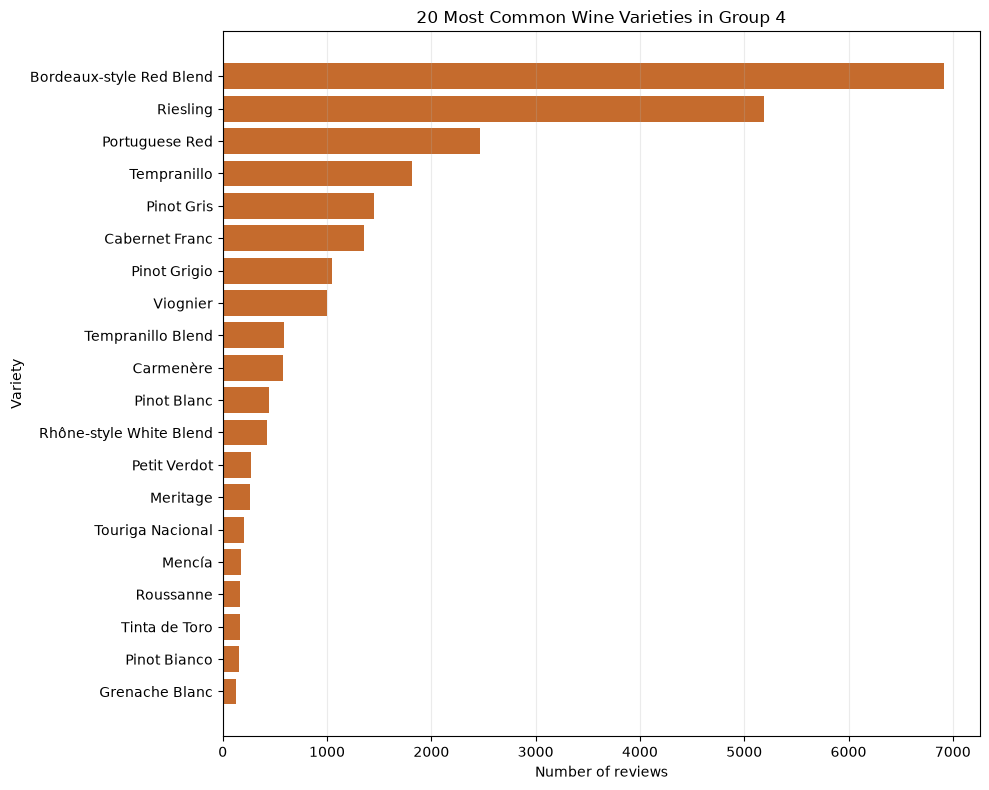

In [32]:
# Review count and share for every target variety.
class_balance = (
    group_4_wines['variety']
    .dropna()
    .value_counts()
    .rename_axis('variety')
    .reset_index(name='review_count')
)
class_balance['percent_of_reviews'] = (
    class_balance['review_count'] / class_balance['review_count'].sum() * 100
).round(2)

display(class_balance)

for minimum_count in [10, 25, 50, 100]:
    retained = class_balance['review_count'].ge(minimum_count).sum()
    print(f'Varieties with at least {minimum_count:>3} reviews: {retained:,}')

fig, ax = plt.subplots(figsize=(10, 8))
top_classes = class_balance.head(20).sort_values('review_count')
ax.barh(top_classes['variety'], top_classes['review_count'], color='#C56B2D')
ax.set_title('20 Most Common Wine Varieties in Group 4')
ax.set_xlabel('Number of reviews')
ax.set_ylabel('Variety')
ax.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()

## Winery analysis

This compares review volume, typical score and price, and score consistency across wineries. Score standard deviation measures consistency: a smaller value means a winery's reviewed wines receive more similar scores.

In [33]:
winery_summary = (
    group_4_wines.dropna(subset=['winery'])
    .groupby('winery')
    .agg(
        review_count=('winery', 'size'),
        average_score=('points', 'mean'),
        score_std_dev=('points', 'std'),
        average_price=('price', 'mean'),
        median_price=('price', 'median'),
    )
    .sort_values('review_count', ascending=False)
    .reset_index()
)
winery_summary[['average_score', 'score_std_dev', 'average_price', 'median_price']] = (
    winery_summary[['average_score', 'score_std_dev', 'average_price', 'median_price']].round(2)
)

display(winery_summary.head(25))

# Limit to wineries with enough reviews before comparing score consistency.
consistent_wineries = (
    winery_summary.query('review_count >= 5')
    .sort_values(['score_std_dev', 'review_count'])
    .head(20)
)
display(consistent_wineries)

,winery,review_count,average_score,score_std_dev,average_price,median_price
0,Wines & Winemakers,102,88.75,2.73,18.17,15.0
1,DFJ Vinhos,98,87.24,2.56,12.32,10.0
2,Dr. Loosen,96,91.35,2.01,47.41,34.0
3,Casa Santos Lima,83,87.58,2.26,16.00,15.0
4,Maximin Grünhäuser,72,90.82,2.39,62.96,43.5
5,Dr. Pauly Bergweiler,67,89.52,2.48,36.18,27.0
6,Domaine Zind-Humbrecht,65,92.57,2.30,62.17,55.0
7,Reichsgraf von Kesselstatt,61,91.26,2.41,38.98,34.0
8,Robert Weil,59,92.58,2.53,173.05,92.0
9,Companhia das Quintas,58,89.84,2.83,27.23,18.5


,winery,review_count,average_score,score_std_dev,average_price,median_price
1090,Cristom,6,91.83,0.41,24.67,25.5
1204,Niedermayr Josef,6,86.83,0.41,20.00,20.0
1244,The Grapes of Roth,6,90.17,0.41,29.67,29.0
1257,Tenuta di Angoris,6,86.83,0.41,14.50,14.5
1264,Pichler-Krutzler,6,93.83,0.41,49.83,50.0
1329,Wallis Family Estate,5,91.80,0.45,69.00,65.0
1345,Illahe,5,87.20,0.45,14.60,15.0
1368,Cuatro Pasos,5,87.80,0.45,13.40,13.0
1369,Dr. Leimbrock,5,89.20,0.45,23.00,19.0
1409,Château Roc de Ségur,5,85.80,0.45,10.40,10.0


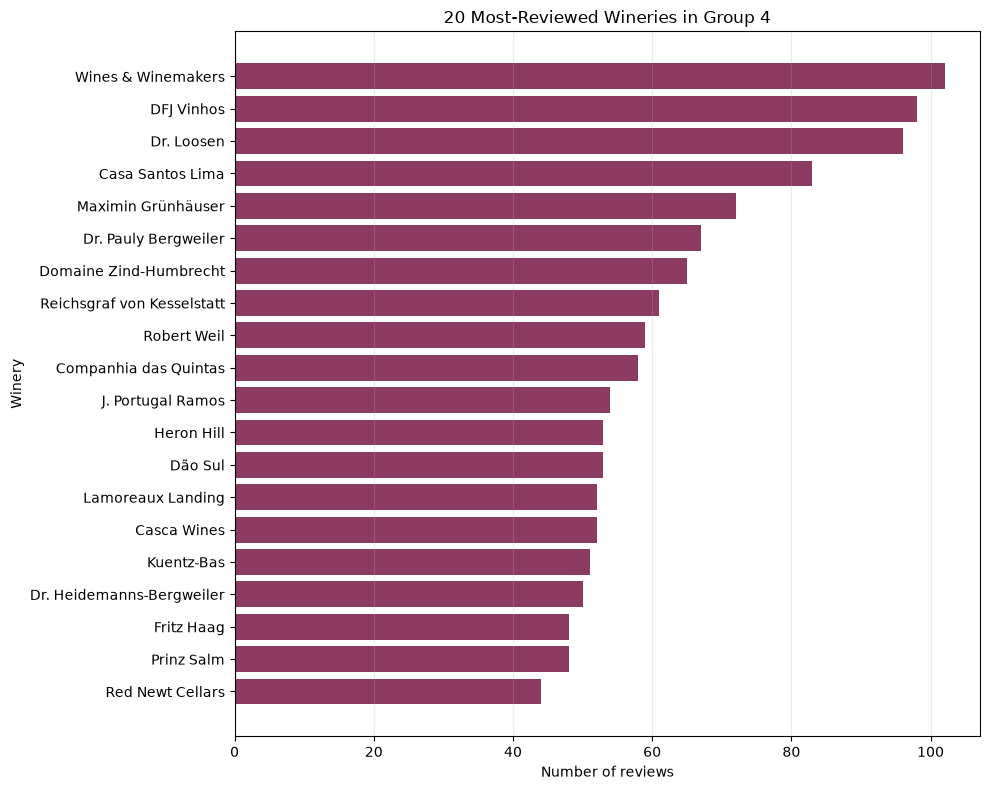

In [34]:
fig, ax = plt.subplots(figsize=(10, 8))
top_wineries = winery_summary.head(20).sort_values('review_count')
ax.barh(top_wineries['winery'], top_wineries['review_count'], color='#8B3A62')
ax.set_title('20 Most-Reviewed Wineries in Group 4')
ax.set_xlabel('Number of reviews')
ax.set_ylabel('Winery')
ax.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()

## Reviewer patterns

Reviewer summaries help reveal different coverage patterns and scoring tendencies.

In [35]:
reviewer_summary = (
    group_4_wines.dropna(subset=['taster_name'])
    .groupby(['taster_name', 'taster_twitter_handle'], dropna=False)
    .agg(
        review_count=('taster_name', 'size'),
        average_score=('points', 'mean'),
        score_std_dev=('points', 'std'),
        average_price=('price', 'mean'),
        unique_varieties=('variety', 'nunique'),
    )
    .sort_values('review_count', ascending=False)
    .reset_index()
)
reviewer_summary[['average_score', 'score_std_dev', 'average_price']] = (
    reviewer_summary[['average_score', 'score_std_dev', 'average_price']].round(2)
)
reviewer_summary

,taster_name,taster_twitter_handle,review_count,average_score,score_std_dev,average_price,unique_varieties
0,Roger Voss,@vossroger,8715,88.81,3.06,33.31,50
1,Michael Schachner,@wineschach,3789,87.72,3.17,32.28,54
2,Anna Lee C. Iijima,NaN,2645,89.07,2.55,32.80,20
3,Paul Gregutt,@paulgwine,2131,88.99,2.73,25.46,38
4,Sean P. Sullivan,@wawinereport,1278,88.70,2.46,33.55,34
5,Anne Krebiehl MW,@AnneInVino,1234,91.07,2.60,33.43,9
6,Joe Czerwinski,@JoeCz,1075,88.65,2.85,39.60,28
7,Virginie Boone,@vboone,788,88.76,2.74,51.43,32
8,Matt Kettmann,@mattkettmann,750,89.21,2.21,33.41,24
9,Jim Gordon,@gordone_cellars,401,88.19,2.46,24.61,28


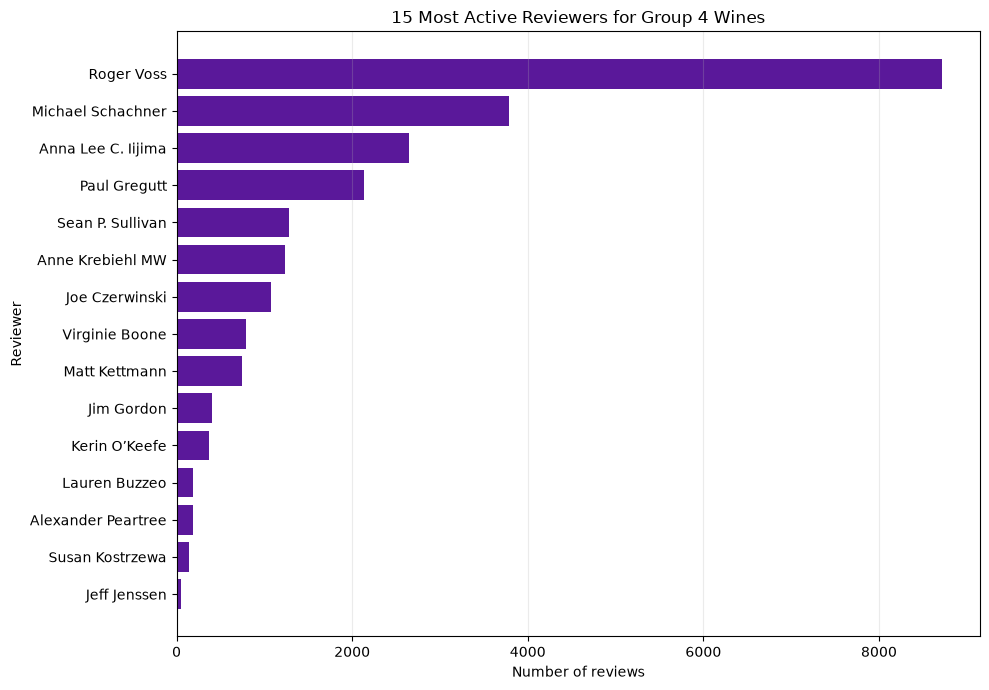

In [36]:
fig, ax = plt.subplots(figsize=(10, 7))
top_reviewers = reviewer_summary.head(15).sort_values('review_count')
ax.barh(top_reviewers['taster_name'], top_reviewers['review_count'], color='#5A189A')
ax.set_title('15 Most Active Reviewers for Group 4 Wines')
ax.set_xlabel('Number of reviews')
ax.set_ylabel('Reviewer')
ax.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()

## Description text EDA

These features show the size and vocabulary of the review text that will later be used to predict variety.

,review_count,mean_word_count,median_word_count
variety,,,
Bordeaux-style Red Blend,6915,40.6,39.0
Riesling,5189,41.2,40.0
Portuguese Red,2466,39.9,39.0
Tempranillo,1810,42.8,42.0
Pinot Gris,1455,39.4,37.0
...,...,...,...
Tinta Amarela,1,52.0,52.0
Tinto Velasco,1,37.0,37.0
Tinta Madeira,1,36.0,36.0


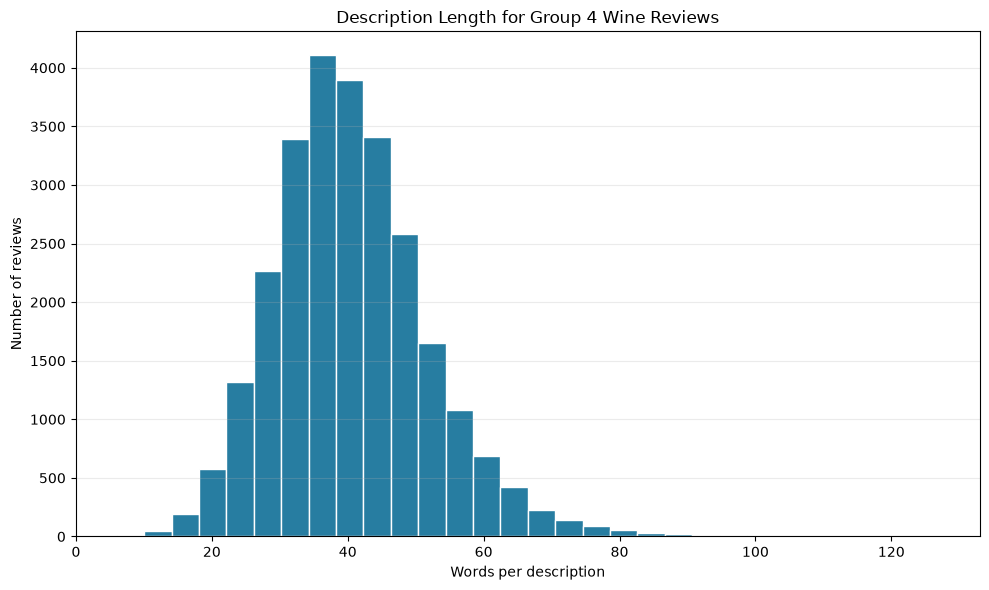

In [37]:
import re
from collections import Counter

text_data = group_4_wines.dropna(subset=['description']).copy()
text_data['description_word_count'] = text_data['description'].str.findall(r"\b[\w'-]+\b").str.len()

description_length_summary = (
    text_data.groupby('variety')['description_word_count']
    .agg(review_count='size', mean_word_count='mean', median_word_count='median')
    .sort_values('review_count', ascending=False)
    .round(1)
)
display(description_length_summary)

fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(text_data['description_word_count'], bins=30, color='#277DA1', edgecolor='white')
ax.set_title('Description Length for Group 4 Wine Reviews')
ax.set_xlabel('Words per description')
ax.set_ylabel('Number of reviews')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

In [38]:
# Common descriptive terms after removing generic English and wine-review words.
stop_words = {
    'a', 'an', 'and', 'are', 'as', 'at', 'be', 'by', 'for', 'from', 'has', 'in',
    'is', 'it', 'its', 'of', 'on', 'or', 'that', 'the', 'this', 'to', 'with',
    'will', 'wine', 'wines', 'flavor', 'flavors', 'finish', 'palate', 'aroma',
    'aromas', 'note', 'notes', 'drink', 'now', 'show', 'shows', 'showing'
}

def top_terms(descriptions, n=15):
    tokens = re.findall(r"\b[a-z][a-z'-]{2,}\b", ' '.join(descriptions).lower())
    counts = Counter(token for token in tokens if token not in stop_words)
    return pd.DataFrame(counts.most_common(n), columns=['term', 'frequency'])

display(top_terms(text_data['description']))

# Compare the most common terms in the five largest variety classes.
largest_varieties = class_balance.head(5)['variety']
top_terms_by_variety = pd.concat(
    [top_terms(text_data.loc[text_data['variety'].eq(variety), 'description'], n=10)
     .assign(variety=variety)
     for variety in largest_varieties],
    ignore_index=True
)
display(top_terms_by_variety[['variety', 'term', 'frequency']])

,term,frequency
0,fruit,9457
1,acidity,7962
2,tannins,7926
3,but,6712
4,ripe,6603
5,it's,6179
6,black,4959
7,fruits,4710
8,dry,4591
9,rich,4059


,variety,term,frequency
0,Bordeaux-style Red Blend,tannins,4007
1,Bordeaux-style Red Blend,fruit,3383
2,Bordeaux-style Red Blend,cabernet,2468
3,Bordeaux-style Red Blend,black,2285
4,Bordeaux-style Red Blend,ripe,2252
5,Bordeaux-style Red Blend,acidity,2190
6,Bordeaux-style Red Blend,fruits,1941
7,Bordeaux-style Red Blend,blend,1591
8,Bordeaux-style Red Blend,merlot,1500
9,Bordeaux-style Red Blend,rich,1456


In [39]:
# Compare vocabulary across score tiers.
text_data['score_tier'] = pd.cut(
    text_data['points'],
    bins=[0, 85, 90, 95, float('inf')],
    labels=['Below 85', '85-89', '90-94', '95+'],
    right=False,
)
top_terms_by_score_tier = pd.concat(
    [top_terms(tier_data['description'], n=12).assign(score_tier=score_tier)
     for score_tier, tier_data in text_data.dropna(subset=['score_tier']).groupby('score_tier', observed=True)],
    ignore_index=True
)
top_terms_by_score_tier[['score_tier', 'term', 'frequency']]

,score_tier,term,frequency
0,Below 85,fruit,770
1,Below 85,but,578
2,Below 85,acidity,536
3,Below 85,tannins,424
4,Below 85,it's,404
5,Below 85,dry,342
6,Below 85,berry,342
7,Below 85,red,318
8,Below 85,nose,313
9,Below 85,sweet,297
